# 01 - Analisis exploratorio de CICIDS2017

Este cuaderno explora el dataset limpio generado por `python -m src.preprocess`. Cubre: resumen de limpieza, desbalance de clases, correlacion entre variables y distribucion de variables clave por clase.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENT.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config
from src.data_loader import load_processed, split_features_target

sns.set_theme(style='whitegrid')
df = load_processed()
X, y, attack = split_features_target(df)
print(df.shape)

(2519404, 71)


## 1. Resumen de limpieza

In [2]:
report = json.loads(config.CLEANING_REPORT_FILE.read_text(encoding='utf-8'))
steps = pd.Series({
    'Filas crudas': report['rows_raw'],
    'Con inf/NaN (eliminadas)': -report['rows_removed_missing'],
    'Duplicados exactos (eliminados)': -report['rows_removed_duplicates'],
    'Etiquetas conflictivas (eliminadas)': -report['rows_removed_conflicting'],
    'Filas finales': report['rows_final'],
})
print(steps.to_string())
print('\nColumnas constantes eliminadas:', report['constant_columns_dropped'])
print('Variables finales:', report['n_features'])

Filas crudas                           2830743
Con inf/NaN (eliminadas)                 -2867
Duplicados exactos (eliminados)        -307078
Etiquetas conflictivas (eliminadas)      -1394
Filas finales                          2519404

Columnas constantes eliminadas: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Variables finales: 69


## 2. Desbalance de clases

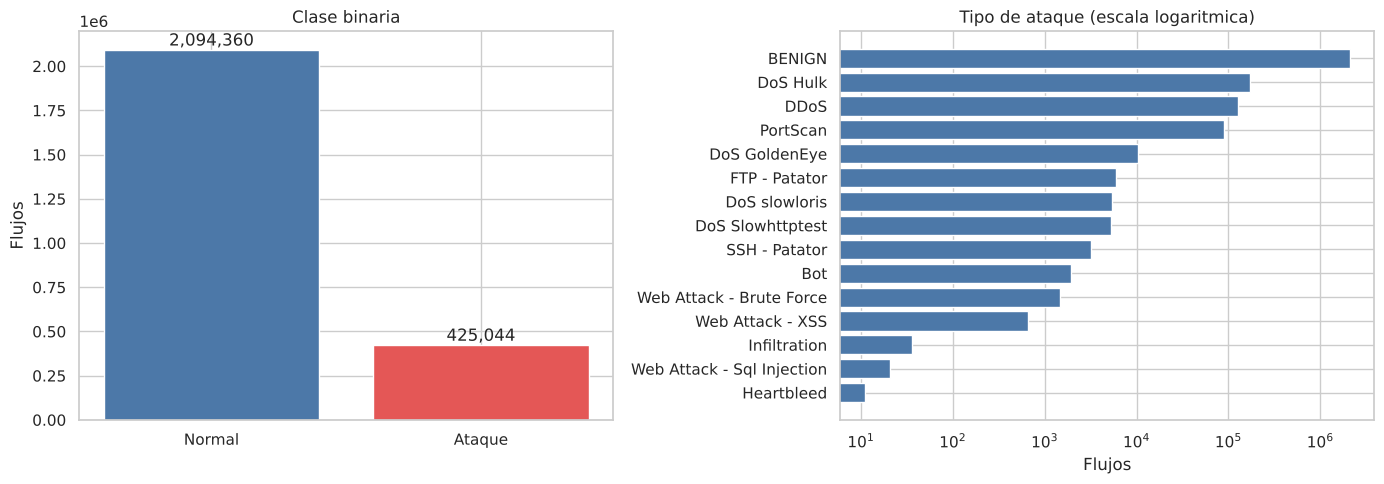

attack_type
BENIGN                        83.1292
DoS Hulk                       6.8555
DDoS                           5.0810
PortScan                       3.5774
DoS GoldenEye                  0.4083
FTP - Patator                  0.2354
DoS slowloris                  0.2137
DoS Slowhttptest               0.2075
SSH - Patator                  0.1278
Bot                            0.0773
Web Attack - Brute Force       0.0583
Web Attack - XSS               0.0259
Infiltration                   0.0014
Web Attack - Sql Injection     0.0008
Heartbleed                     0.0004


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
binary = y.map({0: 'Normal', 1: 'Ataque'}).value_counts()
axes[0].bar(binary.index, binary.values, color=['#4C78A8', '#E45756'])
axes[0].set_title('Clase binaria')
axes[0].set_ylabel('Flujos')
for i, v in enumerate(binary.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
counts = attack.value_counts()
axes[1].barh(counts.index[::-1], counts.values[::-1], color='#4C78A8')
axes[1].set_xscale('log')
axes[1].set_title('Tipo de ataque (escala logaritmica)')
axes[1].set_xlabel('Flujos')
plt.tight_layout()
plt.show()
print((counts / len(df) * 100).round(4).to_string())

Observacion: la clase normal domina (cerca del 83 por ciento) y existen familias muy raras (Heartbleed, Infiltration, SQL Injection). Por eso el split es estratificado por tipo de ataque y la Accuracy es una metrica engañosa en este problema.

## 3. Correlacion entre variables

Pares con |r| > 0.95: 38 de 4761
Fwd URG Flags                CWE Flag Count            1.0000
Total Backward Packets       Subflow Bwd Packets       1.0000
Fwd PSH Flags                SYN Flag Count            1.0000
Total Fwd Packets            Subflow Fwd Packets       1.0000
Fwd Packet Length Mean       Avg Fwd Segment Size      1.0000
Bwd Packet Length Mean       Avg Bwd Segment Size      1.0000
Total Length of Bwd Packets  Subflow Bwd Bytes         1.0000
Total Length of Fwd Packets  Subflow Fwd Bytes         1.0000
Total Fwd Packets            Total Backward Packets    0.9991
                             Subflow Bwd Packets       0.9991

Variables candidatas a eliminar por redundancia: 22


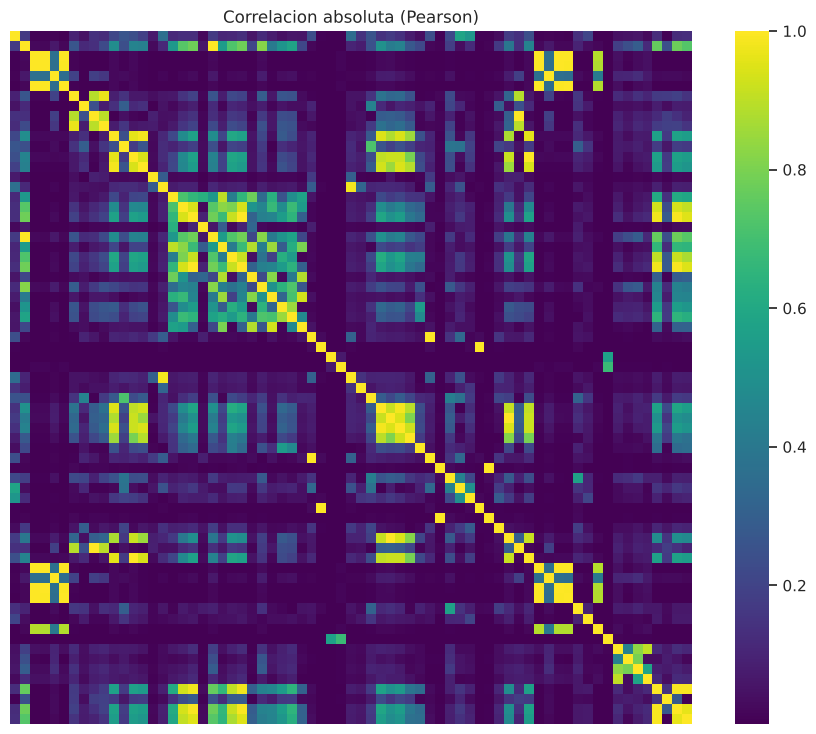

In [4]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print('Pares con |r| > 0.95:', int((pairs > 0.95).sum()), 'de', len(pairs))
print(pairs.head(10).round(4).to_string())
redundant = [c for c in upper.columns if (upper[c] > 0.95).any()]
print('\nVariables candidatas a eliminar por redundancia:', len(redundant))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='viridis', xticklabels=False, yticklabels=False)
plt.title('Correlacion absoluta (Pearson)')
plt.show()

## 4. Distribucion de variables clave por clase

Se usa una muestra estratificada para acelerar el graficado. Las variables se muestran con `log1p` porque tienen colas muy pesadas.

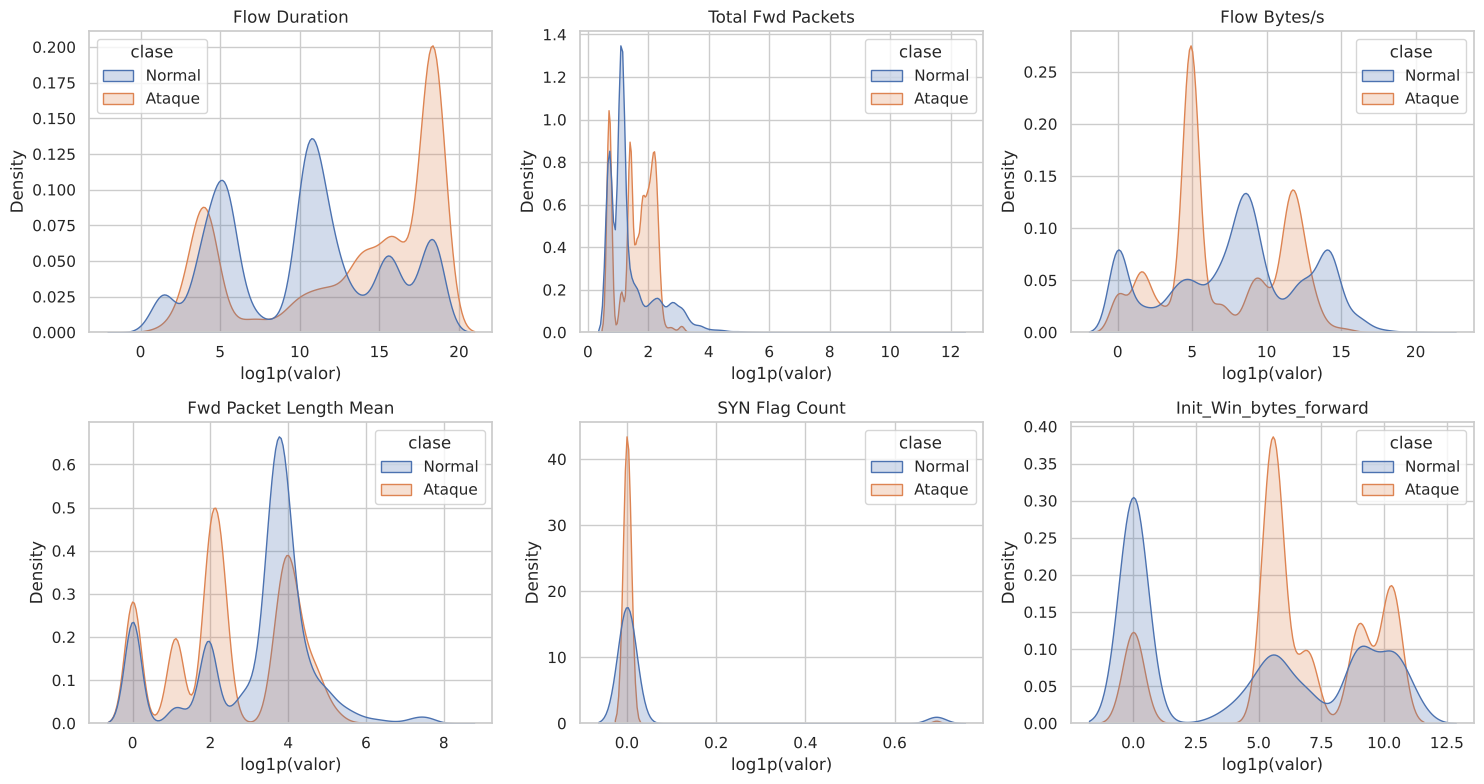

In [5]:
sample = df.groupby(config.LABEL_COLUMN, group_keys=False).sample(n=20000, random_state=config.RANDOM_STATE)
sample = sample.assign(clase=sample[config.LABEL_COLUMN].map({0: 'Normal', 1: 'Ataque'}))
key_features = ['Flow Duration', 'Total Fwd Packets', 'Flow Bytes/s', 'Fwd Packet Length Mean', 'SYN Flag Count', 'Init_Win_bytes_forward']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), key_features):
    values = np.log1p(sample[feature].clip(lower=0))
    sns.kdeplot(data=sample.assign(v=values), x='v', hue='clase', common_norm=False, fill=True, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('log1p(valor)')
plt.tight_layout()
plt.show()

## 5. Valores negativos

Algunas variables contienen valores negativos que no tienen sentido fisico (duracion o tasas negativas) y otros que son centinelas (`Init_Win_bytes_* = -1` indica ausencia de ventana TCP). No se modifican; los modelos basados en arboles los manejan sin problema.

In [6]:
print(pd.Series(report['negative_value_counts']).sort_values(ascending=False).to_string())

Init_Win_bytes_backward    1215365
Init_Win_bytes_forward      911012
Flow IAT Min                  2880
Flow Duration                  107
Flow Packets/s                 107
Flow IAT Mean                  107
Flow IAT Max                   107
Flow Bytes/s                    78
min_seg_size_forward            35
Fwd Header Length               35
Bwd Header Length               22
Fwd IAT Min                     17
